In [4]:
import math

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import text

from prime.config import get_engine

engine = get_engine()


def q(sql: str, **params) -> pd.DataFrame:
    """Выполнить запрос и вернуть DataFrame. Соединение закрывается сразу."""
    try:
        with engine.connect() as conn:
            # Сутки и месяцы считаем по UTC — так они у всех одинаковые.
            conn.execute(text("set time zone 'UTC'"))
            return pd.read_sql(text(sql), conn, params=params)
    finally:
        engine.dispose()


print("подключились как:", q("select current_user as login").iloc[0, 0])

подключились как: aabychkova_1


In [5]:
monthly_revenue = q("""
    SELECT
        DATE_TRUNC(
            'month',
            paid_at AT TIME ZONE 'UTC'
        )::date AS month,

        SUM(amount) AS revenue,

        COUNT(*) AS payments_count,

        ROUND(AVG(amount), 2) AS avg_payment

    FROM prime.payments

    WHERE status = 'success'
      AND paid_at >= '2025-02-01 00:00:00+00'
      AND paid_at < '2026-08-01 00:00:00+00'

    GROUP BY 1
    ORDER BY 1
""")

display(monthly_revenue)

,month,revenue,payments_count,avg_payment
0,2025-02-01,26970400.0,98200,274.65
1,2025-03-01,31718924.0,115476,274.68
2,2025-04-01,32431030.0,117970,274.91
3,2025-05-01,35195819.0,127981,275.01
4,2025-06-01,35633528.0,129672,274.80
5,2025-07-01,38448855.0,139745,275.14
6,2025-08-01,39944116.0,145284,274.94
7,2025-09-01,40038850.0,145750,274.71
8,2025-10-01,42861784.0,156016,274.73
9,2025-11-01,42721885.0,155515,274.71


In [8]:

# Преобразуем месяц в тип даты
monthly_revenue["month"] = pd.to_datetime(
    monthly_revenue["month"]
)

# Сколько календарных дней в каждом месяце?
monthly_revenue["days_in_month"] = (
    monthly_revenue["month"].dt.days_in_month
)

# Среднедневная выручка
monthly_revenue["revenue_per_day"] = (
    monthly_revenue["revenue"]
    / monthly_revenue["days_in_month"]
)

# Изменение месячной выручки к предыдущему месяцу, %
monthly_revenue["revenue_mom_pct"] = (
    monthly_revenue["revenue"].pct_change() * 100
)

# Изменение среднедневной выручки, %
monthly_revenue["daily_mom_pct"] = (
    monthly_revenue["revenue_per_day"].pct_change() * 100
)

numeric_cols = [
    "revenue",
    "revenue_per_day",
    "revenue_mom_pct",
    "daily_mom_pct"
]

result = monthly_revenue[
    ["month"] + numeric_cols
].copy()

result[numeric_cols] = result[numeric_cols].round(2)

display(result)

,month,revenue,revenue_per_day,revenue_mom_pct,daily_mom_pct
0,2025-02-01,26970400.0,963228.57,NaN,NaN
1,2025-03-01,31718924.0,1023191.10,17.61,6.23
2,2025-04-01,32431030.0,1081034.33,2.25,5.65
3,2025-05-01,35195819.0,1135349.00,8.53,5.02
4,2025-06-01,35633528.0,1187784.27,1.24,4.62
5,2025-07-01,38448855.0,1240285.65,7.90,4.42
6,2025-08-01,39944116.0,1288519.87,3.89,3.89
7,2025-09-01,40038850.0,1334628.33,0.24,3.58
8,2025-10-01,42861784.0,1382638.19,7.05,3.60
9,2025-11-01,42721885.0,1424062.83,-0.33,3.00


In [9]:
monthly_clients = q("""
    SELECT
        DATE_TRUNC(
            'month',
            p.paid_at AT TIME ZONE 'UTC'
        )::date AS month,

        COUNT(*) AS payments_count,

        COUNT(DISTINCT s.owner_client_id)
            AS paying_clients,

        ROUND(
            COUNT(*)::numeric /
            NULLIF(
                COUNT(DISTINCT s.owner_client_id),
                0
            ),
            2
        ) AS payments_per_client,

        COUNT(*) FILTER (
            WHERE s.subscription_id IS NULL
        ) AS unmatched_payments

    FROM prime.payments p

    LEFT JOIN prime.subscriptions s
        ON p.subscription_id = s.subscription_id

    WHERE p.status = 'success'
      AND p.paid_at >= '2025-02-01 00:00:00+00'
      AND p.paid_at < '2026-08-01 00:00:00+00'

    GROUP BY 1
    ORDER BY 1
""")

display(monthly_clients)

,month,payments_count,paying_clients,payments_per_client,unmatched_payments
0,2025-02-01,98200,98102,1.00,0
1,2025-03-01,115476,111959,1.03,0
2,2025-04-01,117970,117241,1.01,0
3,2025-05-01,127981,124241,1.03,0
4,2025-06-01,129672,128891,1.01,0
5,2025-07-01,139745,135561,1.03,0
6,2025-08-01,145284,141001,1.03,0
7,2025-09-01,145750,144864,1.01,0
8,2025-10-01,156016,151293,1.03,0
9,2025-11-01,155515,154591,1.01,0


In [10]:

monthly_segments = q("""
    WITH client_months AS (
        SELECT
            s.owner_client_id,

            DATE_TRUNC(
                'month',
                p.paid_at AT TIME ZONE 'UTC'
            )::date AS month,

            SUM(p.amount) AS revenue

        FROM prime.payments p

        JOIN prime.subscriptions s
            ON p.subscription_id = s.subscription_id

        WHERE p.status = 'success'

        GROUP BY 1, 2
    ),

    client_history AS (
        SELECT
            owner_client_id,
            month,
            revenue,

            MIN(month) OVER (
                PARTITION BY owner_client_id
            ) AS first_month

        FROM client_months
    )

    SELECT
        month,

        COUNT(*) FILTER (
            WHERE month = first_month
        ) AS new_clients,

        COUNT(*) FILTER (
            WHERE month > first_month
        ) AS existing_clients,

        COALESCE(SUM(revenue) FILTER (
            WHERE month = first_month
        ), 0) AS new_revenue,

        COALESCE(SUM(revenue) FILTER (
            WHERE month > first_month
        ), 0) AS existing_revenue

    FROM client_history

    WHERE month >= '2025-02-01'
      AND month < '2026-08-01'

    GROUP BY month
    ORDER BY month
""")

display(monthly_segments)

,month,new_clients,existing_clients,new_revenue,existing_revenue
0,2025-02-01,26993,71109,7416979.0,19553421.0
1,2025-03-01,12292,99667,3507033.0,28211891.0
2,2025-04-01,10805,106436,3000116.0,29430914.0
3,2025-05-01,11187,113054,3173278.0,32022541.0
4,2025-06-01,10846,118045,2991696.0,32641832.0
5,2025-07-01,11189,124372,3174694.0,35274161.0
6,2025-08-01,11216,129785,3148453.0,36795663.0
7,2025-09-01,10640,134224,2929498.0,37109352.0
8,2025-10-01,11321,139972,3207526.0,39654258.0
9,2025-11-01,10682,143909,2969043.0,39752842.0


In [11]:

# Создаём копию таблицы
check = monthly_segments.copy()

# Приводим месяц к типу datetime
check["month"] = pd.to_datetime(check["month"])

# Считаем выручку двух групп
check["total_revenue"] = (
    check["new_revenue"]
    + check["existing_revenue"]
)

# Сравниваем с первоначальным расчётом выручки
check = check.merge(
    monthly_revenue[["month", "revenue"]],
    on="month",
    validate="one_to_one"
)

# Проверяем, что выручка не потерялась
assert (
    (check["total_revenue"] - check["revenue"])
    .abs()
    .max() < 0.01
)

# Доля выручки от ранее плативших клиентов
check["existing_share_pct"] = (
    check["existing_revenue"]
    / check["total_revenue"] * 100
)

display(
    check[
        ["month", "total_revenue", "existing_share_pct"]
    ].assign(
        month=lambda df: df["month"].dt.strftime("%Y-%m"),
        existing_share_pct=lambda df: df["existing_share_pct"].round(2)
    )
)

,month,total_revenue,existing_share_pct
0,2025-02,26970400.0,72.50
1,2025-03,31718924.0,88.94
2,2025-04,32431030.0,90.75
3,2025-05,35195819.0,90.98
4,2025-06,35633528.0,91.60
5,2025-07,38448855.0,91.74
6,2025-08,39944116.0,92.12
7,2025-09,40038850.0,92.68
8,2025-10,42861784.0,92.52
9,2025-11,42721885.0,93.05


In [12]:

july_clients = q("""
    WITH client_revenue AS (
        SELECT
            s.owner_client_id,

            COUNT(*) FILTER (
                WHERE p.paid_at >= '2025-07-01'
                  AND p.paid_at < '2025-08-01'
            ) AS payments_2025,

            COUNT(*) FILTER (
                WHERE p.paid_at >= '2026-07-01'
                  AND p.paid_at < '2026-08-01'
            ) AS payments_2026,

            SUM(p.amount) FILTER (
                WHERE p.paid_at >= '2025-07-01'
                  AND p.paid_at < '2025-08-01'
            ) AS revenue_2025,

            SUM(p.amount) FILTER (
                WHERE p.paid_at >= '2026-07-01'
                  AND p.paid_at < '2026-08-01'
            ) AS revenue_2026

        FROM prime.payments p

        JOIN prime.subscriptions s
            ON p.subscription_id = s.subscription_id

        WHERE p.status = 'success'
          AND (
              (p.paid_at >= '2025-07-01'
               AND p.paid_at < '2025-08-01')
              OR
              (p.paid_at >= '2026-07-01'
               AND p.paid_at < '2026-08-01')
          )

        GROUP BY s.owner_client_id
    ),

    grouped AS (
        SELECT
            CASE
                WHEN payments_2025 > 0
                 AND payments_2026 > 0
                    THEN '1. Оба периода'

                WHEN payments_2025 = 0
                    THEN '2. Только июль 2026'

                ELSE '3. Только июль 2025'
            END AS client_group,

            COALESCE(revenue_2025, 0) AS revenue_2025,
            COALESCE(revenue_2026, 0) AS revenue_2026

        FROM client_revenue
    )

    SELECT
        client_group,
        COUNT(*) AS clients,
        SUM(revenue_2025) AS revenue_2025,
        SUM(revenue_2026) AS revenue_2026,
        SUM(revenue_2026 - revenue_2025) AS delta_revenue

    FROM grouped

    GROUP BY client_group
    ORDER BY client_group
""")

display(july_clients)

,client_group,clients,revenue_2025,revenue_2026,delta_revenue
0,1. Оба периода,81003,22987096.0,27180901.0,4193805.0
1,2. Только июль 2026,108154,0.0,36218089.0,36218089.0
2,3. Только июль 2025,54558,15461759.0,0.0,-15461759.0


In [13]:

only_2026_detail = q("""
    WITH paid AS (
        SELECT
            s.owner_client_id,
            p.paid_at,
            p.amount
        FROM prime.payments p
        JOIN prime.subscriptions s
            ON p.subscription_id = s.subscription_id
        WHERE p.status = 'success'
          AND p.paid_at < '2026-08-01 00:00:00+00'
    ),

    first_payments AS (
        SELECT
            owner_client_id,
            MIN(paid_at) AS first_paid_at
        FROM paid
        GROUP BY owner_client_id
    ),

    july_2025 AS (
        SELECT DISTINCT owner_client_id
        FROM paid
        WHERE paid_at >= '2025-07-01 00:00:00+00'
          AND paid_at < '2025-08-01 00:00:00+00'
    ),

    july_2026 AS (
        SELECT
            owner_client_id,
            SUM(amount) AS revenue
        FROM paid
        WHERE paid_at >= '2026-07-01 00:00:00+00'
          AND paid_at < '2026-08-01 00:00:00+00'
        GROUP BY owner_client_id
    )

    SELECT
        CASE
            WHEN f.first_paid_at >=
                 '2025-08-01 00:00:00+00'
                THEN '1. Новые после июля 2025'
            ELSE '2. Платили до августа 2025'
        END AS client_group,

        COUNT(*) AS clients,
        SUM(j.revenue) AS revenue_2026

    FROM july_2026 j

    JOIN first_payments f
        ON j.owner_client_id = f.owner_client_id

    LEFT JOIN july_2025 old
        ON j.owner_client_id = old.owner_client_id

    WHERE old.owner_client_id IS NULL

    GROUP BY 1
    ORDER BY 1
""")

display(only_2026_detail)

,client_group,clients,revenue_2026
0,1. Новые после июля 2025,104818,35108166.0
1,2. Платили до августа 2025,3336,1109923.0


In [14]:

# Используем названия групп как индексы
base = july_clients.set_index("client_group")
detail = only_2026_detail.set_index("client_group")

# Собираем вклады четырёх групп
factors = pd.DataFrame({
    "group": [
        "Платили в обоих июлях",
        "Начали платить после июля 2025",
        "Платили ранее, но не в июле 2025",
        "Платили только в июле 2025"
    ],

    "contribution": [
        base.loc["1. Оба периода", "delta_revenue"],
        detail.loc["1. Новые после июля 2025", "revenue_2026"],
        detail.loc["2. Платили до августа 2025", "revenue_2026"],
        base.loc["3. Только июль 2025", "delta_revenue"]
    ]
})

# Фактическое изменение выручки
actual_change = (
    monthly_revenue.loc[
        monthly_revenue["month"] == "2026-07-01",
        "revenue"
    ].iloc[0]
    -
    monthly_revenue.loc[
        monthly_revenue["month"] == "2025-07-01",
        "revenue"
    ].iloc[0]
)

# Проверяем, что декомпозиция сошлась
assert abs(
    factors["contribution"].sum() - actual_change
) < 0.01

display(factors)

print("Изменение выручки:", actual_change)
print("Сумма факторов:", factors["contribution"].sum())

,group,contribution
0,Платили в обоих июлях,4193805.0
1,Начали платить после июля 2025,35108166.0
2,"Платили ранее, но не в июле 2025",1109923.0
3,Платили только в июле 2025,-15461759.0


Изменение выручки: 24950135.0
Сумма факторов: 24950135.0


In [15]:

# Клиенты, впервые заплатившие после июля 2025
cohort = only_2026_detail.loc[
    only_2026_detail["client_group"]
    == "1. Новые после июля 2025"
].iloc[0]

# Клиенты, впервые заплатившие именно в июле 2026
july_new = monthly_segments.loc[
    pd.to_datetime(monthly_segments["month"])
    == pd.Timestamp("2026-07-01")
].iloc[0]

# Повторные плательщики внутри нашей группы
repeat_clients = (
    cohort["clients"] - july_new["new_clients"]
)

repeat_revenue = (
    cohort["revenue_2026"] - july_new["new_revenue"]
)

repeat_share = (
    repeat_revenue / cohort["revenue_2026"] * 100
)

print("Повторных плательщиков:", repeat_clients)
print("Выручка от повторных платежей:", repeat_revenue)
print("Доля повторной выручки:", round(repeat_share, 2), "%")

Повторных плательщиков: 93600
Выручка от повторных платежей: 31352338.0
Доля повторной выручки: 89.3 %


In [16]:

cohort_repeat = q("""
    WITH paid AS (
        SELECT
            s.owner_client_id,
            p.paid_at
        FROM prime.payments p
        JOIN prime.subscriptions s
            ON p.subscription_id = s.subscription_id
        WHERE p.status = 'success'
          AND p.paid_at < '2026-08-01 00:00:00+00'
    ),

    first_paid AS (
        SELECT
            owner_client_id,
            MIN(paid_at) AS first_paid_at
        FROM paid
        GROUP BY owner_client_id
    ),

    client_repeat AS (
        SELECT
            f.owner_client_id,

            DATE_TRUNC(
                'month',
                f.first_paid_at AT TIME ZONE 'UTC'
            )::date AS cohort_month,

            BOOL_OR(
                p.paid_at >=
                    f.first_paid_at + INTERVAL '20 days'
                AND
                p.paid_at <
                    f.first_paid_at + INTERVAL '45 days'
            ) AS paid_again

        FROM first_paid f
        JOIN paid p
            ON f.owner_client_id = p.owner_client_id

        WHERE f.first_paid_at >=
              '2025-02-01 00:00:00+00'
          AND f.first_paid_at <
              '2026-06-01 00:00:00+00'

        GROUP BY
            f.owner_client_id,
            f.first_paid_at
    )

    SELECT
        cohort_month,

        COUNT(*) AS cohort_size,

        COUNT(*) FILTER (
            WHERE paid_again
        ) AS repeated_clients,

        ROUND(
            COUNT(*) FILTER (
                WHERE paid_again
            ) * 100.0 / COUNT(*),
            2
        ) AS repeat_rate_pct

    FROM client_repeat
    GROUP BY cohort_month
    ORDER BY cohort_month
""")

display(cohort_repeat)

,cohort_month,cohort_size,repeated_clients,repeat_rate_pct
0,2025-02-01,26993,25018,92.68
1,2025-03-01,12292,11640,94.70
2,2025-04-01,10805,10224,94.62
3,2025-05-01,11187,10563,94.42
4,2025-06-01,10846,10293,94.90
5,2025-07-01,11189,10574,94.50
6,2025-08-01,11216,10614,94.63
7,2025-09-01,10640,10059,94.54
8,2025-10-01,11321,10673,94.28
9,2025-11-01,10682,10096,94.51


In [17]:

cohort_channels = q("""
    WITH paid AS (
        SELECT
            s.owner_client_id,
            p.paid_at
        FROM prime.payments p
        JOIN prime.subscriptions s
            ON p.subscription_id = s.subscription_id
        WHERE p.status = 'success'
          AND p.paid_at < '2026-08-01 00:00:00+00'
    ),

    first_paid AS (
        SELECT
            owner_client_id,
            MIN(paid_at) AS first_paid_at
        FROM paid
        GROUP BY owner_client_id
    ),

    client_repeat AS (
        SELECT
            f.owner_client_id,

            DATE_TRUNC(
                'month',
                f.first_paid_at AT TIME ZONE 'UTC'
            )::date AS cohort_month,

            COALESCE(
                c.acquisition_channel,
                'unknown'
            ) AS channel,

            BOOL_OR(
                p.paid_at >=
                    f.first_paid_at + INTERVAL '20 days'
                AND p.paid_at <
                    f.first_paid_at + INTERVAL '45 days'
            ) AS paid_again

        FROM first_paid f

        JOIN paid p
            ON f.owner_client_id = p.owner_client_id

        LEFT JOIN prime.clients c
            ON f.owner_client_id = c.client_id

        WHERE f.first_paid_at >=
              '2026-02-01 00:00:00+00'
          AND f.first_paid_at <
              '2026-05-01 00:00:00+00'

        GROUP BY
            f.owner_client_id,
            f.first_paid_at,
            c.acquisition_channel
    )

    SELECT
        cohort_month,
        channel,
        COUNT(*) AS cohort_size,

        COUNT(*) FILTER (
            WHERE paid_again
        ) AS repeated_clients,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE paid_again
            ) / COUNT(*),
            2
        ) AS repeat_rate_pct

    FROM client_repeat
    GROUP BY cohort_month, channel
    ORDER BY cohort_month, channel
""")

display(cohort_channels)

,cohort_month,channel,cohort_size,repeated_clients,repeat_rate_pct
0,2026-02-01,crm,1247,1184,94.95
1,2026-02-01,organic,2390,2282,95.48
2,2026-02-01,partner_telecom,1769,1673,94.57
3,2026-02-01,performance,2216,2080,93.86
4,2026-02-01,referral,787,743,94.41
5,2026-02-01,social,1592,1508,94.72
6,2026-02-01,unknown,199,191,95.98
7,2026-03-01,crm,1319,1181,89.54
8,2026-03-01,organic,2600,2327,89.50
9,2026-03-01,partner_telecom,2057,1827,88.82


In [18]:

# Выбираем февральскую и мартовскую когорты
df = cohort_channels.copy()
df["cohort_month"] = pd.to_datetime(df["cohort_month"])

feb = df[
    df["cohort_month"] == "2026-02-01"
].set_index("channel")

mar = df[
    df["cohort_month"] == "2026-03-01"
].set_index("channel")

# Убеждаемся, что сравниваем одинаковые каналы
assert set(feb.index) == set(mar.index)

# Вес каждого канала в общей когорте
w0 = feb["cohort_size"] / feb["cohort_size"].sum()
w1 = mar["cohort_size"] / mar["cohort_size"].sum()

# Доля повторных платежей внутри каждого канала
p0 = feb["repeated_clients"] / feb["cohort_size"]
p1 = mar["repeated_clients"] / mar["cohort_size"]

# Фактор изменения структуры каналов
structure_effect = ((w1 - w0) * p0).sum() * 100

# Фактор изменения доли повторных платежей
within_effect = (w1 * (p1 - p0)).sum() * 100

# Фактическое изменение общей доли
actual_change = (
    (w1 * p1).sum() - (w0 * p0).sum()
) * 100

# Проверка декомпозиции
assert abs(
    structure_effect + within_effect - actual_change
) < 1e-9

print("Структура:", round(structure_effect, 3), "п. п.")
print("Внутри каналов:", round(within_effect, 3), "п. п.")
print("Общее изменение:", round(actual_change, 3), "п. п.")


Структура: 0.003 п. п.
Внутри каналов: -5.954 п. п.
Общее изменение: -5.951 п. п.


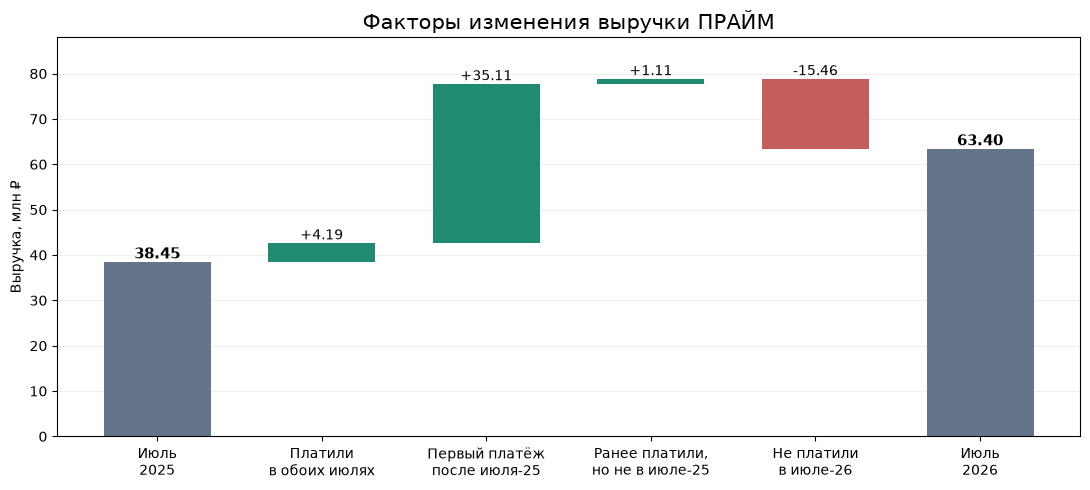

In [20]:

import matplotlib.pyplot as plt
import numpy as np

# Выручка в начале и конце сравнения
revenue_2025 = 38_448_855
revenue_2026 = 63_398_990

# Берём факторы из уже рассчитанной таблицы
changes = factors["contribution"].to_numpy()

# Рассчитываем положение каждого столбца
current = revenue_2025
bottoms = []
heights = []

for change in changes:
    next_value = current + change

    bottoms.append(min(current, next_value))
    heights.append(abs(change))

    current = next_value

# Проверяем итог
assert abs(current - revenue_2026) < 0.01

# Все значения переводим в миллионы рублей
values = [
    revenue_2025,
    *heights,
    revenue_2026
]

bases = [0, *bottoms, 0]

values = np.array(values) / 1_000_000
bases = np.array(bases) / 1_000_000

labels = [
    "Июль\n2025",
    "Платили\nв обоих июлях",
    "Первый платёж\nпосле июля-25",
    "Ранее платили,\nно не в июле-25",
    "Не платили\nв июле-26",
    "Июль\n2026"
]


colors = [
    "#64748b",
    "#218b72",
    "#218b72",
    "#218b72",
    "#c65d5d",
    "#64748b"
]

fig, ax = plt.subplots(figsize=(11, 5))

ax.bar(
    labels,
    values,
    bottom=bases,
    color=colors,
    width=0.65
)

ax.set_title(
    "Факторы изменения выручки ПРАЙМ",
    fontsize=15
)

ax.set_ylabel("Выручка, млн ₽")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)


# Подписываем вклад каждого фактора
for i, change in enumerate(changes, start=1):
    ax.text(
        i,
        bases[i] + values[i] + 0.8,
        f"{change / 1_000_000:+.2f}",
        ha="center",
        fontsize=10
    )

# Подписываем начальную и конечную выручку
for i in [0, len(values) - 1]:
    ax.text(
        i,
        values[i] + 0.8,
        f"{values[i]:.2f}",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

# Оставляем место для подписей
ax.set_ylim(0, 88)

plt.tight_layout()
plt.show()

In [21]:
tariffs = q("""
    SELECT
        tariff_id,
        tariff_name,
        monthly_fee,
        valid_from,
        valid_to
    FROM prime.tariffs
    ORDER BY tariff_id, valid_from
""")

display(tariffs)

,tariff_id,tariff_name,monthly_fee,valid_from,valid_to
0,1,Базовый,199.0,2024-01-01,2026-02-28
1,1,Базовый,249.0,2026-03-01,2030-12-31
2,2,Расширенный,399.0,2024-01-01,2026-02-28
3,2,Расширенный,429.0,2026-02-01,2026-06-30
4,2,Расширенный,449.0,2026-03-01,2030-12-31


In [22]:

monthly_churn = q("""
    WITH months AS (
        SELECT generate_series(
            TIMESTAMPTZ '2025-03-01 00:00:00+00',
            TIMESTAMPTZ '2026-07-01 00:00:00+00',
            INTERVAL '1 month'
        ) AS month_start
    ),

    first_payment AS (
        SELECT
            subscription_id,
            MIN(paid_at) AS first_paid_at
        FROM prime.payments
        WHERE status = 'success'
        GROUP BY subscription_id
    ),

    active_base AS (
        SELECT
            (m.month_start AT TIME ZONE 'UTC')::date AS month,
            m.month_start,
            s.subscription_id,
            s.ended_at

        FROM months m

        JOIN prime.subscriptions s
            ON s.started_at < m.month_start
           AND (
               s.ended_at IS NULL
               OR s.ended_at >= m.month_start
           )

        JOIN first_payment fp
            ON fp.subscription_id = s.subscription_id
           AND fp.first_paid_at < m.month_start
    )

    SELECT
        month,

        COUNT(*) AS active_subscriptions,

        COUNT(*) FILTER (
            WHERE ended_at >= month_start
              AND ended_at < month_start + INTERVAL '1 month'
        ) AS cancellations,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE ended_at >= month_start
                  AND ended_at < month_start + INTERVAL '1 month'
            ) / NULLIF(COUNT(*), 0),
            2
        ) AS cancellation_rate_pct

    FROM active_base
    GROUP BY month
    ORDER BY month
""")

display(monthly_churn)

,month,active_subscriptions,cancellations,cancellation_rate_pct
0,2025-03-01,104178,4283,4.11
1,2025-04-01,112018,4553,4.06
2,2025-05-01,118164,4987,4.22
3,2025-06-01,124226,5041,4.06
4,2025-07-01,129930,5284,4.07
5,2025-08-01,135713,5531,4.08
6,2025-09-01,141290,5608,3.97
7,2025-10-01,146221,5917,4.05
8,2025-11-01,151498,5960,3.93
9,2025-12-01,156106,6233,3.99


In [23]:
# Создаём аналитическую копию справочника
tariffs_clean = tariffs.loc[
    tariffs["monthly_fee"] != 429
].copy()

In [24]:

display(tariffs_clean)

print("Строк до очистки:", len(tariffs))
print("Строк после очистки:", len(tariffs_clean))

assert len(tariffs_clean) == 4
assert 429 not in tariffs_clean["monthly_fee"].values


,tariff_id,tariff_name,monthly_fee,valid_from,valid_to
0,1,Базовый,199.0,2024-01-01,2026-02-28
1,1,Базовый,249.0,2026-03-01,2030-12-31
2,2,Расширенный,399.0,2024-01-01,2026-02-28
4,2,Расширенный,449.0,2026-03-01,2030-12-31


Строк до очистки: 5
Строк после очистки: 4


In [25]:
payment_amounts = q("""
    SELECT
        DATE_TRUNC(
            'month',
            p.paid_at AT TIME ZONE 'UTC'
        )::date AS month,

        s.tariff_id,

        p.amount,

        COUNT(*) AS payments_count

    FROM prime.payments p

    JOIN prime.subscriptions s
        ON p.subscription_id = s.subscription_id

    WHERE p.status = 'success'
      AND p.paid_at >= '2026-02-01 00:00:00+00'
      AND p.paid_at < '2026-05-01 00:00:00+00'

    GROUP BY 1, 2, 3
    ORDER BY 1, 2, 3
""")

display(payment_amounts)

,month,tariff_id,amount,payments_count
0,2026-02-01,1,199.0,98241
1,2026-02-01,2,399.0,60024
2,2026-03-01,1,249.0,111289
3,2026-03-01,2,449.0,67969
4,2026-04-01,1,249.0,102644
5,2026-04-01,2,449.0,62869


In [26]:
df = payment_amounts.copy()
df["month"] = pd.to_datetime(df["month"])

# Выбираем февральские и мартовские платежи
feb = df[
    df["month"] == "2026-02-01"
].set_index("tariff_id")

mar = df[
    df["month"] == "2026-03-01"
].set_index("tariff_id")

# Проверяем сопоставимость тарифов
assert feb.index.is_unique
assert mar.index.is_unique
assert set(feb.index) == set(mar.index)

# Фактическая выручка
revenue_feb = (
    feb["payments_count"] * feb["amount"]
).sum()

revenue_mar = (
    mar["payments_count"] * mar["amount"]
).sum()

# Мартовские платежи по февральским ценам
revenue_old_prices = (
    mar["payments_count"] * feb["amount"]
).sum()

# Вклады факторов
quantity_mix_effect = revenue_old_prices - revenue_feb
price_effect = revenue_mar - revenue_old_prices

# Проверка
assert abs(
    quantity_mix_effect + price_effect
    - (revenue_mar - revenue_feb)
) < 0.01

print("Количество и структура:", quantity_mix_effect)
print("Цены:", price_effect)
print("Общий прирост:", revenue_mar - revenue_feb)

Количество и структура: 5766607.0
Цены: 8962900.0
Общий прирост: 14729507.0


In [28]:
# Приводим даты в обеих таблицах к одному типу
monthly_clients["month"] = pd.to_datetime(
    monthly_clients["month"]
)

monthly_revenue["month"] = pd.to_datetime(
    monthly_revenue["month"]
)

# Теперь объединяем таблицы
metrics = monthly_clients[
    ["month", "paying_clients", "payments_count"]
].merge(
    monthly_revenue[["month", "revenue"]],
    on="month",
    validate="one_to_one"
)

metrics = metrics.set_index("month")

display(metrics.head())

# Объединяем помесячные показатели
metrics = monthly_clients[
    ["month", "paying_clients", "payments_count"]
].merge(
    monthly_revenue[["month", "revenue"]],
    on="month",
    validate="one_to_one"
)

metrics["month"] = pd.to_datetime(metrics["month"])
metrics = metrics.set_index("month")

# Выбираем два сравниваемых месяца
base = metrics.loc["2025-07-01"]
current = metrics.loc["2026-07-01"]

# Базовый период
N0 = base["paying_clients"]
F0 = base["payments_count"] / N0
A0 = base["revenue"] / base["payments_count"]

# Сравниваемый период
N1 = current["paying_clients"]
F1 = current["payments_count"] / N1
A1 = current["revenue"] / current["payments_count"]

# Факторная декомпозиция
effect_clients = (N1 - N0) * F0 * A0
effect_frequency = N1 * (F1 - F0) * A0
effect_payment = N1 * F1 * (A1 - A0)

# Проверяем сумму факторов
actual_change = current["revenue"] - base["revenue"]

assert abs(
    effect_clients + effect_frequency
    + effect_payment - actual_change
) < 0.01

print("Количество клиентов:", round(effect_clients, 2))
print("Частота платежей:", round(effect_frequency, 2))
print("Средний платёж:", round(effect_payment, 2))
print("Общий прирост:", actual_change)

,paying_clients,payments_count,revenue
month,,,
2025-02-01,98102,98200,26970400.0
2025-03-01,111959,115476,31718924.0
2025-04-01,117241,117970,32431030.0
2025-05-01,124241,127981,35195819.0
2025-06-01,128891,129672,35633528.0


Количество клиентов: 15201310.35
Частота платежей: 31584.26
Средний платёж: 9717240.39
Общий прирост: 24950135.0


In [29]:

# Результат факторной декомпозиции
revenue_factors = pd.DataFrame({
    "factor": [
        "Количество платящих клиентов",
        "Частота платежей",
        "Средний платёж"
    ],
    "effect_rub": [
        effect_clients,
        effect_frequency,
        effect_payment
    ]
})

# Доля каждого фактора в общем изменении
revenue_factors["share_pct"] = (
    revenue_factors["effect_rub"]
    / actual_change * 100
)

# Проверяем итог
assert abs(
    revenue_factors["effect_rub"].sum()
    - actual_change
) < 0.01

display(
    revenue_factors.round({
        "effect_rub": 2,
        "share_pct": 2
    })
)


,factor,effect_rub,share_pct
0,Количество платящих клиентов,15201310.35,60.93
1,Частота платежей,31584.26,0.13
2,Средний платёж,9717240.39,38.95


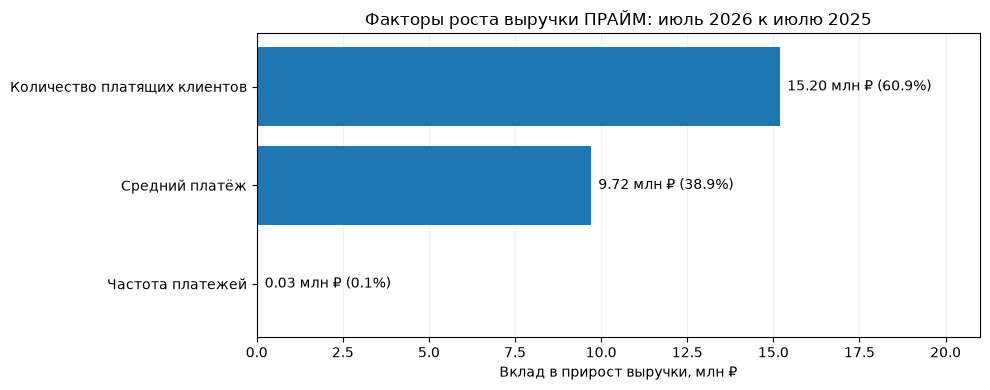

In [30]:

# Сортируем факторы по размеру вклада
plot_data = revenue_factors.sort_values(
    "effect_rub",
    ascending=True
).copy()

fig, ax = plt.subplots(figsize=(10, 4))

bars = ax.barh(
    plot_data["factor"],
    plot_data["effect_rub"] / 1_000_000
)

# Подписываем сумму и долю каждого фактора
for bar, (_, row) in zip(
    bars,
    plot_data.iterrows()
):
    ax.text(
        bar.get_width() + 0.2,
        bar.get_y() + bar.get_height() / 2,
        f'{row["effect_rub"] / 1_000_000:.2f} млн ₽ '
        f'({row["share_pct"]:.1f}%)',
        va="center"
    )

ax.set_title(
    "Факторы роста выручки ПРАЙМ: "
    "июль 2026 к июлю 2025"
)

ax.set_xlabel("Вклад в прирост выручки, млн ₽")
ax.set_xlim(0, 21)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

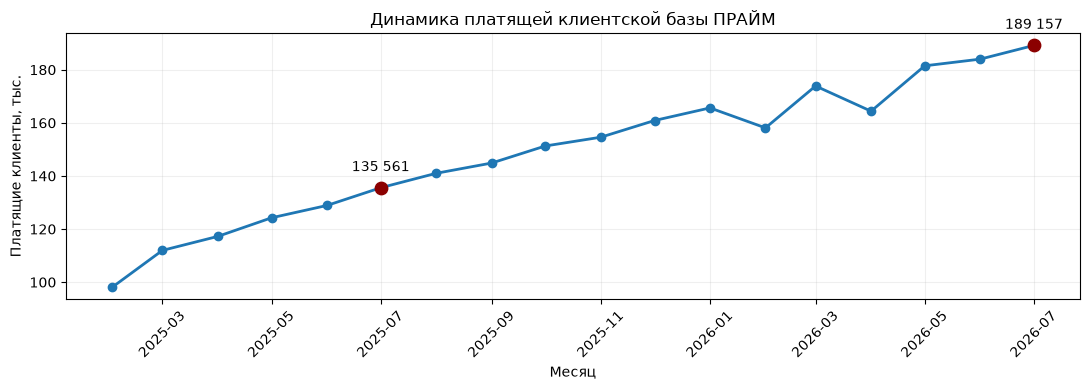

In [31]:

# Динамика количества платящих клиентов
trend = metrics.sort_index().copy()

fig, ax = plt.subplots(figsize=(11, 4))

ax.plot(
    trend.index,
    trend["paying_clients"] / 1000,
    marker="o",
    linewidth=2
)

# Выделяем месяцы, которые сравниваем
for month in ["2025-07-01", "2026-07-01"]:
    date = pd.Timestamp(month)
    clients = trend.loc[date, "paying_clients"]

    ax.scatter(
        date,
        clients / 1000,
        color="darkred",
        s=80,
        zorder=3
    )

    ax.annotate(
        f"{clients:,}".replace(",", " "),
        (date, clients / 1000),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center"
    )

ax.set_title(
    "Динамика платящей клиентской базы ПРАЙМ"
)
ax.set_ylabel("Платящие клиенты, тыс.")
ax.set_xlabel("Месяц")
ax.grid(alpha=0.2)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

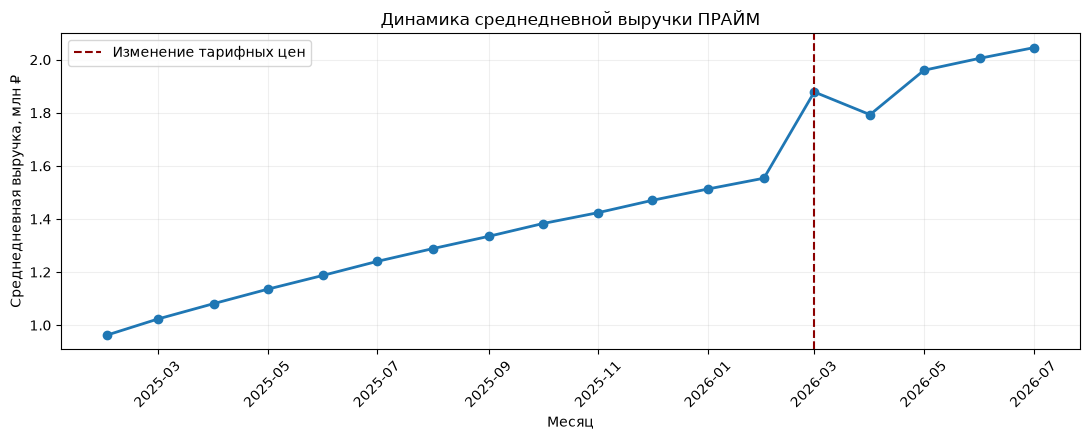

In [32]:

# Копируем помесячные показатели
daily_trend = metrics.sort_index().copy()

# Вычисляем среднюю выручку за календарный день
daily_trend["revenue_per_day"] = (
    daily_trend["revenue"]
    / daily_trend.index.days_in_month
)

fig, ax = plt.subplots(figsize=(11, 4.5))

ax.plot(
    daily_trend.index,
    daily_trend["revenue_per_day"] / 1_000_000,
    marker="o",
    linewidth=2
)

# Отмечаем месяц изменения тарифных цен
price_change = pd.Timestamp("2026-03-01")

ax.axvline(
    price_change,
    color="darkred",
    linestyle="--",
    linewidth=1.5,
    label="Изменение тарифных цен"
)

ax.set_title(
    "Динамика среднедневной выручки ПРАЙМ"
)
ax.set_ylabel("Среднедневная выручка, млн ₽")
ax.set_xlabel("Месяц")
ax.grid(alpha=0.2)
ax.legend()

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [35]:

client_flows = q("""
    WITH paid AS (
        SELECT
            DATE_TRUNC(
                'month',
                p.paid_at AT TIME ZONE 'UTC'
            )::date AS month,
            s.owner_client_id AS client_id

        FROM prime.payments p
        JOIN prime.subscriptions s
            ON p.subscription_id = s.subscription_id

        WHERE p.status = 'success'
          AND p.paid_at < '2026-08-01 00:00:00+00'

        GROUP BY 1, 2
    ),

    first_paid AS (
        SELECT
            client_id,
            MIN(month) AS first_month
        FROM paid
        GROUP BY client_id
    ),

    classified AS (
        SELECT
            cur.month,
            cur.client_id,

            CASE
                WHEN f.first_month = cur.month
                    THEN 'first'
                WHEN prev.client_id IS NOT NULL
                    THEN 'retained'
                ELSE 'reactivated'
            END AS client_group

        FROM paid cur

        JOIN first_paid f
            ON cur.client_id = f.client_id

        LEFT JOIN paid prev
            ON cur.client_id = prev.client_id
           AND prev.month = (
               cur.month - INTERVAL '1 month'
           )::date
    ),

    current_flows AS (
        SELECT
            month,
            COUNT(*) AS paying_clients,

            COUNT(*) FILTER (
                WHERE client_group = 'first'
            ) AS first_time_clients,

            COUNT(*) FILTER (
                WHERE client_group = 'retained'
            ) AS retained_clients,

            COUNT(*) FILTER (
                WHERE client_group = 'reactivated'
            ) AS reactivated_clients

        FROM classified
        GROUP BY month
    ),

    previous_flows AS (
        SELECT
            (
                prev.month + INTERVAL '1 month'
            )::date AS month,

            COUNT(*) AS previous_month_clients,

            COUNT(*) FILTER (
                WHERE cur.client_id IS NULL
            ) AS stopped_paying

        FROM paid prev

        LEFT JOIN paid cur
            ON cur.client_id = prev.client_id
           AND cur.month = (
               prev.month + INTERVAL '1 month'
           )::date

        GROUP BY 1
    )

    SELECT
        c.month,
        c.paying_clients,
        c.first_time_clients,
        c.retained_clients,
        c.reactivated_clients,
        p.stopped_paying,

        ROUND(
            100.0 * c.retained_clients
            / NULLIF(p.previous_month_clients, 0),
            2
        ) AS monthly_repeat_rate_pct

    FROM current_flows c

    JOIN previous_flows p
        ON c.month = p.month

    WHERE c.month BETWEEN
    DATE '2025-07-01'
    AND DATE '2026-07-01'

    ORDER BY c.month
""")

display(client_flows)

,month,paying_clients,first_time_clients,retained_clients,reactivated_clients,stopped_paying,monthly_repeat_rate_pct
0,2025-07-01,135561,11189,118564,5808,10327,91.99
1,2025-08-01,141001,11216,124653,5132,10908,91.95
2,2025-09-01,144864,10640,128719,5505,12282,91.29
3,2025-10-01,151293,11321,133357,6615,11507,92.06
4,2025-11-01,154591,10682,138081,5828,13212,91.27
5,2025-12-01,160880,11477,142312,7091,12279,92.06
6,2026-01-01,165623,11340,148053,6230,12827,92.03
7,2026-02-01,158103,10200,141698,6205,23925,85.55
8,2026-03-01,173875,11241,145331,17303,12772,91.92
9,2026-04-01,164391,10077,148002,6312,25873,85.12


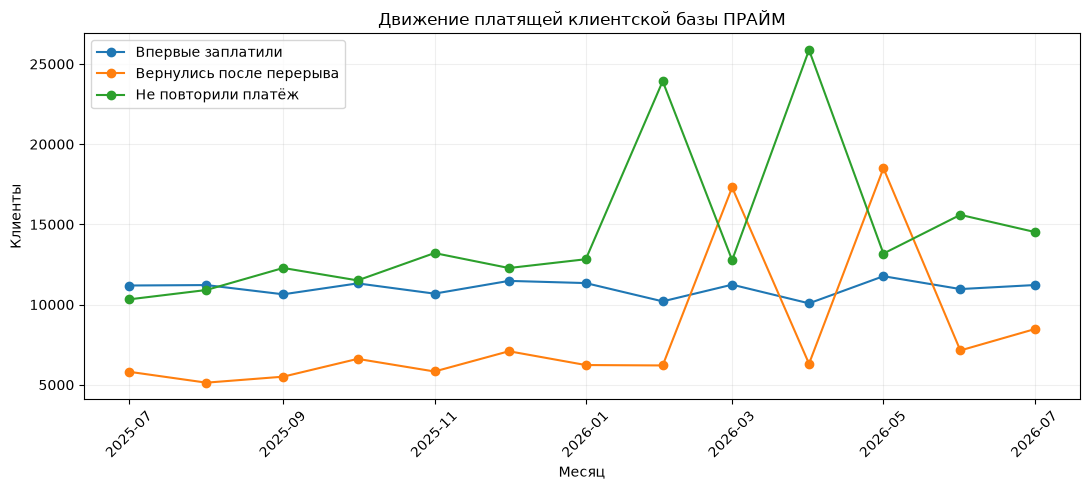

In [36]:

flows = client_flows.copy()
flows["month"] = pd.to_datetime(flows["month"])

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    flows["month"],
    flows["first_time_clients"],
    marker="o",
    label="Впервые заплатили"
)

ax.plot(
    flows["month"],
    flows["reactivated_clients"],
    marker="o",
    label="Вернулись после перерыва"
)

ax.plot(
    flows["month"],
    flows["stopped_paying"],
    marker="o",
    label="Не повторили платёж"
)

ax.set_title(
    "Движение платящей клиентской базы ПРАЙМ"
)

ax.set_ylabel("Клиенты")
ax.set_xlabel("Месяц")
ax.grid(alpha=0.2)
ax.legend()

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [37]:

calendar_gaps = q("""
    WITH paid AS (
        SELECT
            DATE_TRUNC(
                'month',
                p.paid_at AT TIME ZONE 'UTC'
            )::date AS month,

            s.owner_client_id AS client_id,

            BOOL_OR(
                EXTRACT(
                    DAY FROM p.paid_at AT TIME ZONE 'UTC'
                ) = 31
            ) AS paid_on_31st

        FROM prime.payments p

        JOIN prime.subscriptions s
            ON p.subscription_id = s.subscription_id

        WHERE p.status = 'success'
          AND p.paid_at >= '2026-01-01 00:00:00+00'
          AND p.paid_at < '2026-06-01 00:00:00+00'

        GROUP BY 1, 2
    ),

    periods AS (
        SELECT
            DATE '2026-01-01' AS previous_month,
            DATE '2026-02-01' AS skipped_month,
            DATE '2026-03-01' AS next_month

        UNION ALL

        SELECT
            DATE '2026-03-01',
            DATE '2026-04-01',
            DATE '2026-05-01'
    )

    SELECT
        periods.skipped_month,

        COUNT(*) FILTER (
            WHERE skipped.client_id IS NULL
        ) AS skipped_clients,

        COUNT(*) FILTER (
            WHERE skipped.client_id IS NULL
              AND nxt.client_id IS NOT NULL
        ) AS returned_next_month,

        COUNT(*) FILTER (
            WHERE skipped.client_id IS NULL
              AND nxt.client_id IS NOT NULL
              AND prev.paid_on_31st
              AND nxt.paid_on_31st
        ) AS paid_on_31st_both

    FROM periods

    JOIN paid prev
        ON prev.month = periods.previous_month

    LEFT JOIN paid skipped
        ON skipped.month = periods.skipped_month
       AND skipped.client_id = prev.client_id

    LEFT JOIN paid nxt
        ON nxt.month = periods.next_month
       AND nxt.client_id = prev.client_id

    GROUP BY periods.skipped_month
    ORDER BY periods.skipped_month
""")

display(calendar_gaps)

,skipped_month,skipped_clients,returned_next_month,paid_on_31st_both
0,2026-02-01,23925,16780,837
1,2026-04-01,25873,17764,439


In [38]:

gap_payment_attempts = q("""
    WITH paid AS (
        SELECT DISTINCT
            DATE_TRUNC(
                'month',
                p.paid_at AT TIME ZONE 'UTC'
            )::date AS month,
            s.owner_client_id AS client_id

        FROM prime.payments p
        JOIN prime.subscriptions s
            ON p.subscription_id = s.subscription_id

        WHERE p.status = 'success'
          AND p.paid_at >= '2026-01-01 00:00:00+00'
          AND p.paid_at < '2026-06-01 00:00:00+00'
    ),

    periods AS (
        SELECT
            DATE '2026-01-01' AS previous_month,
            DATE '2026-02-01' AS skipped_month

        UNION ALL

        SELECT
            DATE '2026-03-01',
            DATE '2026-04-01'
    ),

    skipped AS (
        SELECT
            per.skipped_month,
            prev.client_id

        FROM periods per

        JOIN paid prev
            ON prev.month = per.previous_month

        LEFT JOIN paid cur
            ON cur.client_id = prev.client_id
           AND cur.month = per.skipped_month

        WHERE cur.client_id IS NULL
    ),

    attempts AS (
        SELECT
            sk.skipped_month,
            sk.client_id,

            COUNT(p.payment_id) AS attempts_count,

            COUNT(p.payment_id) FILTER (
                WHERE p.status <> 'success'
            ) AS non_success_count

        FROM skipped sk

        LEFT JOIN prime.subscriptions s
            ON s.owner_client_id = sk.client_id

        LEFT JOIN prime.payments p
            ON p.subscription_id = s.subscription_id
           AND p.paid_at >= (
               sk.skipped_month::timestamp
               AT TIME ZONE 'UTC'
           )
           AND p.paid_at < (
               (sk.skipped_month + INTERVAL '1 month')
               AT TIME ZONE 'UTC'
           )

        GROUP BY 1, 2
    )

    SELECT
        skipped_month,
        COUNT(*) AS skipped_clients,

        COUNT(*) FILTER (
            WHERE attempts_count = 0
        ) AS no_recorded_attempts,

        COUNT(*) FILTER (
            WHERE non_success_count > 0
        ) AS had_non_success_attempts

    FROM attempts

    GROUP BY skipped_month
    ORDER BY skipped_month
""")

display(gap_payment_attempts)

,skipped_month,skipped_clients,no_recorded_attempts,had_non_success_attempts
0,2026-02-01,23925,17158,6767
1,2026-04-01,25873,18786,7087
